In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


In [3]:
df = pd.read_csv('/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv', encoding='latin-1')

df = df[['v1', 'v2']].copy()

df.columns = ['label', 'message']

df = df.dropna()

df.head()


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:

df['label'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

print(df['label'].value_counts())


label
0    4825
1     747
Name: count, dtype: int64


In [5]:

X = df['message']
y = df['label'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [6]:

vectorizer = TfidfVectorizer(max_features=5000)

X_train = vectorizer.fit_transform(X_train)
X_test = vectorizer.transform(X_test)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)


Training: (4457, 5000)
Testing: (1115, 5000)


In [7]:

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))


In [8]:

# Number of samples and features
n_samples, n_features = X_train.shape

# Initialize weights and bias
w = np.zeros(n_features)
b = 0

# Hyperparameters
learning_rate = 0.01
epochs = 100

beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8

# Initialize first moment
mw = np.zeros(n_features)
mb = 0

# Initialize second moment
vw = np.zeros(n_features)
vb = 0

# Store loss
loss_history = []

# Adam Optimizer
for epoch in range(1, epochs + 1):

    # Forward propagation
    z = X_train @ w + b
    y_pred = sigmoid(z)

    # Calculate error
    error = y_pred - y_train

    # Calculate gradients
    dw = np.asarray(X_train.T @ error).ravel() / n_samples
    db = np.mean(error)

    # Update first moment
    mw = beta1 * mw + (1 - beta1) * dw
    mb = beta1 * mb + (1 - beta1) * db

    # Update second moment
    vw = beta2 * vw + (1 - beta2) * (dw ** 2)
    vb = beta2 * vb + (1 - beta2) * (db ** 2)

    # Bias correction
    mw_corrected = mw / (1 - beta1 ** epoch)
    mb_corrected = mb / (1 - beta1 ** epoch)

    vw_corrected = vw / (1 - beta2 ** epoch)
    vb_corrected = vb / (1 - beta2 ** epoch)

    # Update weights and bias
    w = w - learning_rate * mw_corrected / (np.sqrt(vw_corrected) + epsilon)

    b = b - learning_rate * mb_corrected / (np.sqrt(vb_corrected) + epsilon)

    # Calculate loss
    z = X_train @ w + b
    y_pred = sigmoid(z)

    loss_epsilon = 1e-15

    loss = -np.mean(
        y_train * np.log(y_pred + loss_epsilon) +
        (1 - y_train) * np.log(1 - y_pred + loss_epsilon)
    )

    loss_history.append(loss)

print("Final Training Loss:", loss_history[-1])


Final Training Loss: 0.13253408859418445


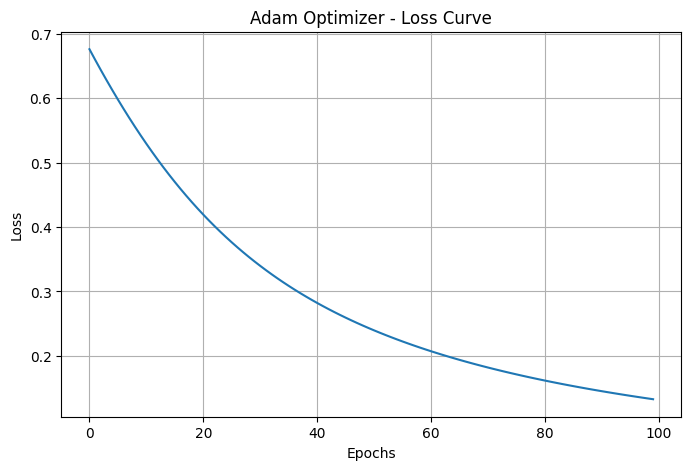

In [9]:

plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Adam Optimizer - Loss Curve")

plt.grid()
plt.show()


In [10]:

# Predictions
y_prob = sigmoid(X_test @ w + b)

y_pred = (y_prob >= 0.5).astype(int)

# Evaluation Metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

# Test Loss
test_loss = -np.mean(
    y_test * np.log(y_prob + 1e-15) +
    (1 - y_test) * np.log(1 - y_prob + 1e-15)
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)
print("Loss:", test_loss)


Accuracy: 0.9695067264573991
Precision: 0.9831932773109243
Recall: 0.785234899328859
F1-Score: 0.8731343283582089
Loss: 0.1653732465704082
